In [1]:
import os
import random
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

In [2]:
SEED = 42

def set_seed(seed=SEED):
    random.seed(seed)
    np.random.seed(seed)
    os.environ['PYTHONHASHSEED'] = str(seed)

set_seed(SEED)

In [12]:
file_paths = {
    "Lokasyon 1": "Location1.csv",
    "Lokasyon 2": "Location2.csv",
    "Lokasyon 3": "Location3.csv",
    "Lokasyon 4": "Location4.csv"
}

datasets = {}

print(" VERİ SETLERİ ÖZET VE İSTATİSTİK ANALİZ ")

# Veri setlerinin özellikleri
for name, path in file_paths.items():
    df = pd.read_csv(path)
    datasets[name] = df
    
    print(f"\n=== {name.upper()} ===")
    print(f"Özellikler: {df.shape}")
    print(f"Sütunlar: {df.columns.tolist()}")
    print(f"Eksik veriler: {df['Time'].isnull().sum() + df.isnull().sum().sum()}")
    print(f"Tekrarlanan veriler: {df.duplicated().sum()}")
    print(f"Tarih aralığı: {df['Time'].min()} → {df['Time'].max()}")
    print("\nPower İstatistikleri:")
    print(df["Power"].describe())
    print("\nRüzgar hızı (100m) İstatistikleri:")
    print(df["windspeed_100m"].describe())
    print("-" * 40)

 VERİ SETLERİ ÖZET VE İSTATİSTİK ANALİZ 

=== LOKASYON 1 ===
Özellikler: (43800, 10)
Sütunlar: ['Time', 'temperature_2m', 'relativehumidity_2m', 'dewpoint_2m', 'windspeed_10m', 'windspeed_100m', 'winddirection_10m', 'winddirection_100m', 'windgusts_10m', 'Power']
Eksik veriler: 0
Tekrarlanan veriler: 0
Tarih aralığı: 2017-01-02 00:00:00 → 2021-12-31 23:00:00

Power İstatistikleri:
count    43800.000000
mean         0.405385
std          0.288322
min          0.000000
25%          0.148900
50%          0.347650
75%          0.659600
max          0.991300
Name: Power, dtype: float64

Rüzgar hızı (100m) İstatistikleri:
count    43800.000000
mean         6.284431
std          2.685216
min          0.100000
25%          4.380000
50%          6.080000
75%          7.990000
max         20.650000
Name: windspeed_100m, dtype: float64
----------------------------------------

=== LOKASYON 2 ===
Özellikler: (43800, 10)
Sütunlar: ['Time', 'temperature_2m', 'relativehumidity_2m', 'dewpoint_2m', 'wi

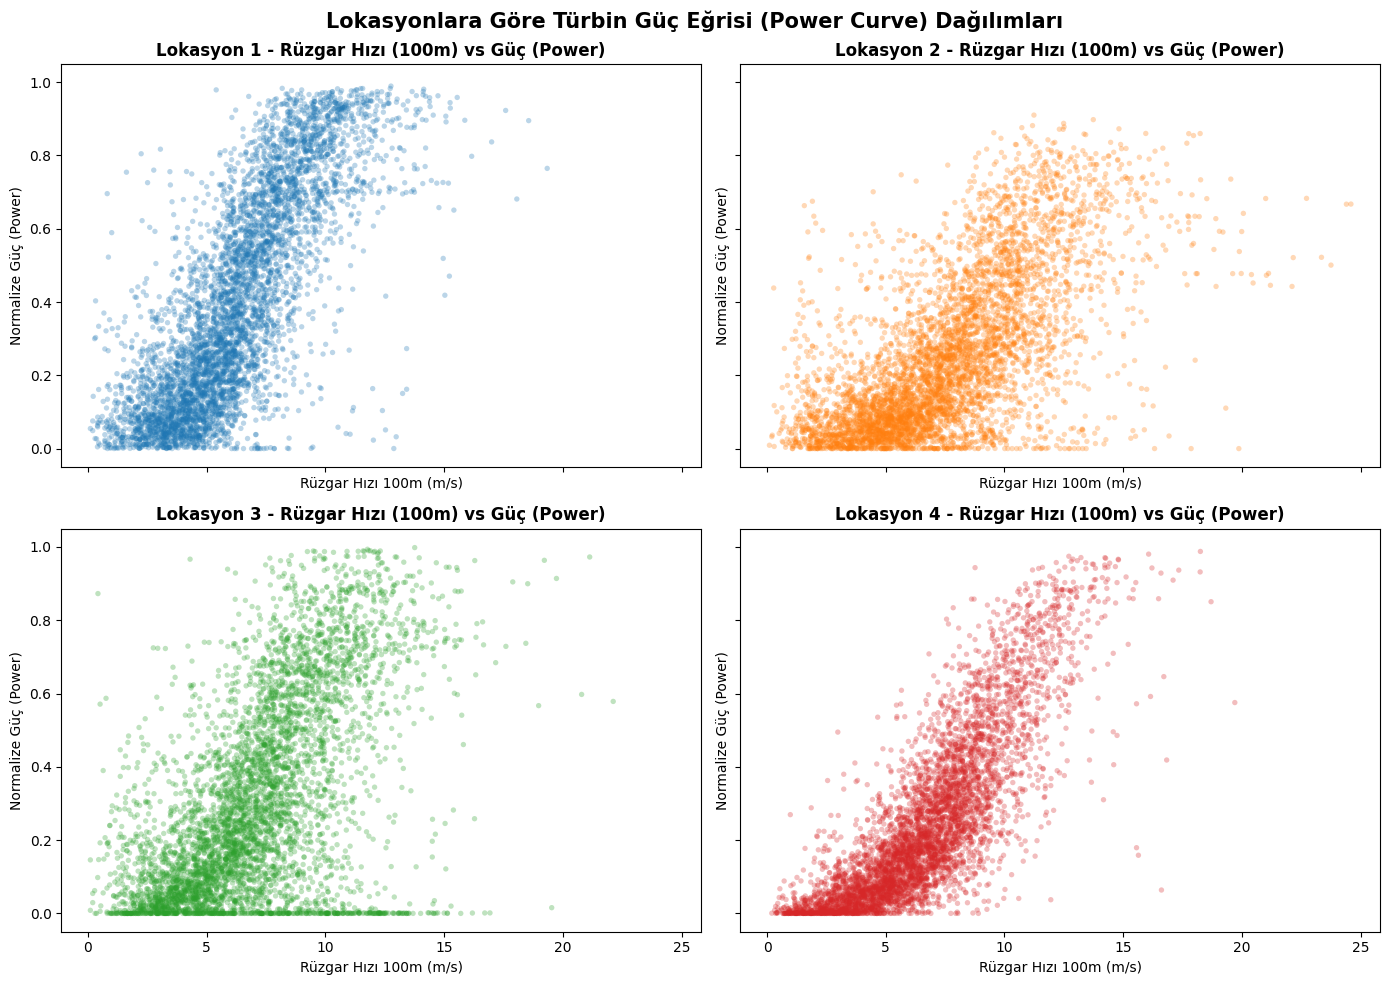

In [7]:
# GÜÇ EĞRİLERİ GRAFİKLERİ
fig, axes = plt.subplots(2, 2, figsize=(14, 10), sharex=True, sharey=True)
axes = axes.flatten()

colors = ['#1f77b4', '#ff7f0e', '#2ca02c', '#d62728']

for idx, (name, df) in enumerate(datasets.items()):
    ax = axes[idx]
    # Örneklemi hafifletmek ve görsel karmaşayı önlemek için Seed ile rastgele 5000 nokta çiziyoruz
    sample_df = df.sample(n=min(5000, len(df)), random_state=SEED)
    
    ax.scatter(sample_df['windspeed_100m'], sample_df['Power'], 
               alpha=0.3, color=colors[idx], edgecolors='none', s=15)
    
    ax.set_title(f"{name} - Rüzgar Hızı (100m) vs Güç (Power)", fontsize=12, fontweight='bold')
    ax.set_xlabel("Rüzgar Hızı 100m (m/s)")
    ax.set_ylabel("Normalize Güç (Power)")
    ax.set_ylim(-0.05, 1.05)

plt.suptitle("Lokasyonlara Göre Türbin Güç Eğrisi (Power Curve) Dağılımları", fontsize=15, fontweight='bold', y=0.98)
plt.tight_layout()
plt.savefig("power_curve_comparison.png", dpi=300)
plt.show()

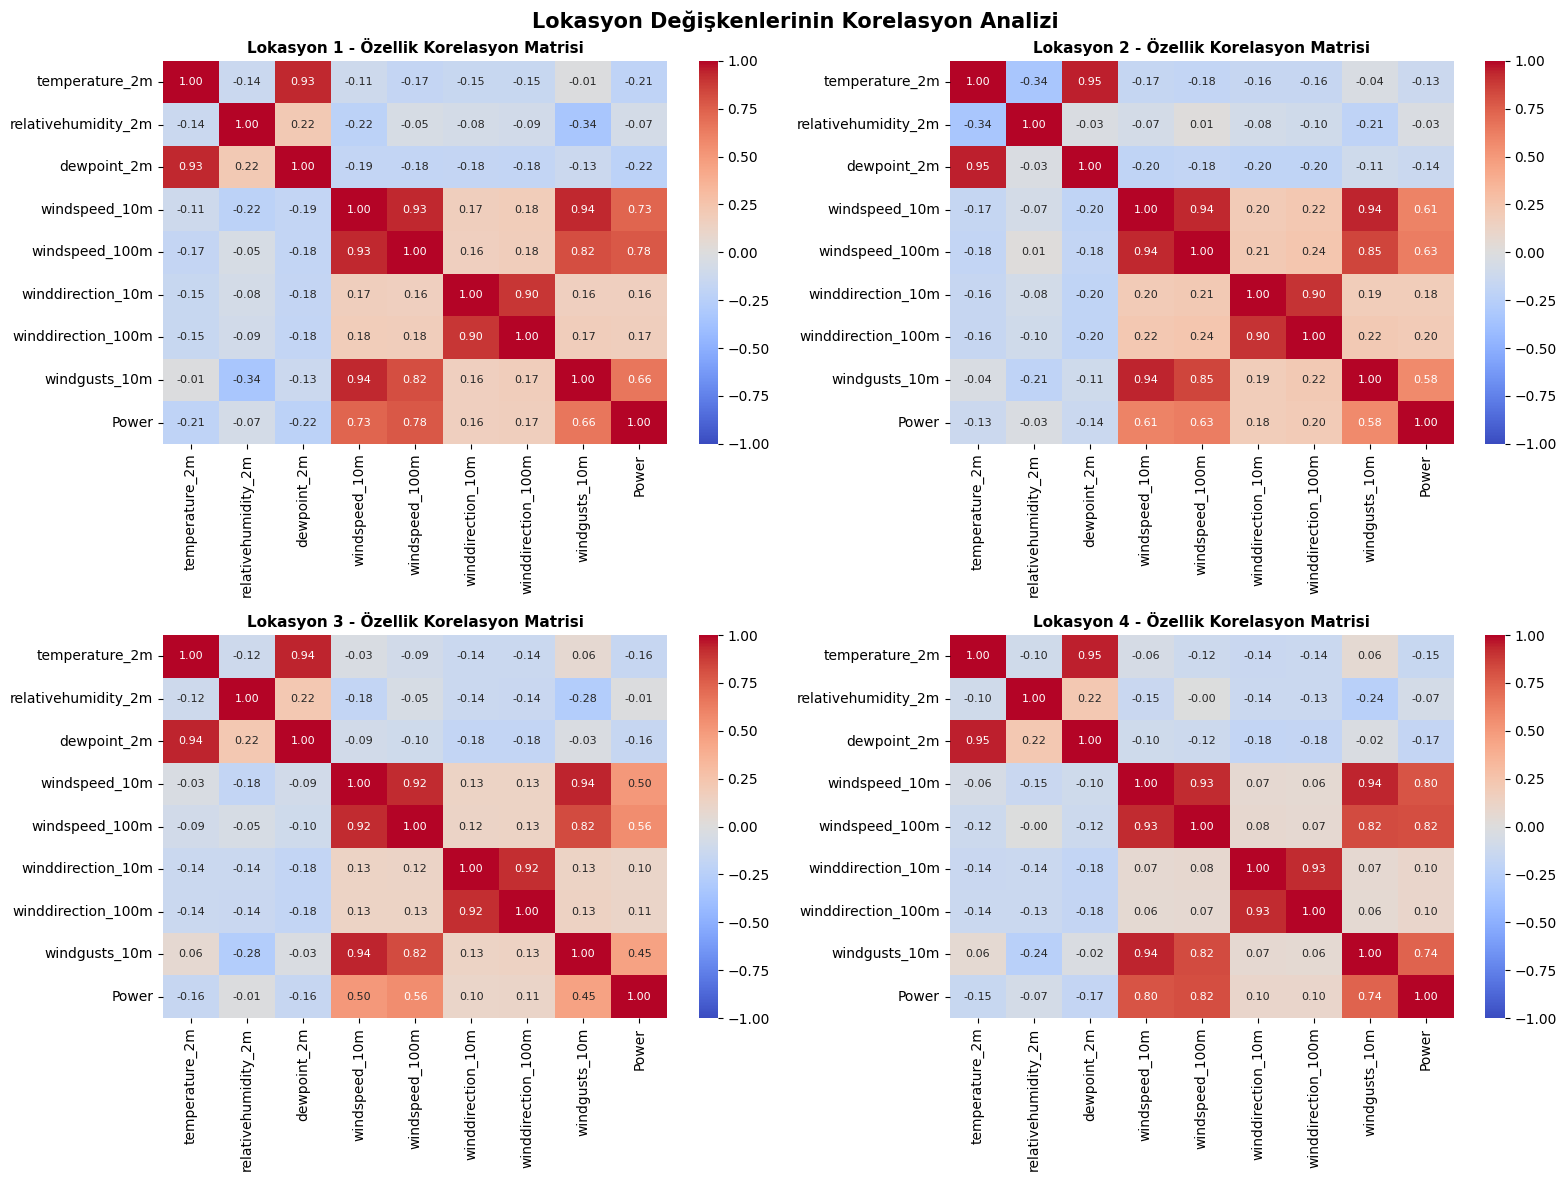

In [6]:
# KORELASYON MATRİSLERİ
fig, axes = plt.subplots(2, 2, figsize=(16, 12))
axes = axes.flatten()

for idx, (name, df) in enumerate(datasets.items()):
    ax = axes[idx]
    # Sayısal sütunların korelasyonu (Time haric tutulur)
    numeric_cols = df.select_dtypes(include=[np.number]).columns
    corr = df[numeric_cols].corr()
    
    sns.heatmap(corr, ax=ax, annot=True, fmt=".2f", cmap="coolwarm", 
                vmin=-1, vmax=1, cbar=True, annot_kws={"size": 8})
    
    ax.set_title(f"{name} - Özellik Korelasyon Matrisi", fontsize=11, fontweight='bold')

plt.suptitle("Lokasyon Değişkenlerinin Korelasyon Analizi", fontsize=15, fontweight='bold', y=0.98)
plt.tight_layout()
plt.savefig("correlation_matrices.png", dpi=300)
plt.show()


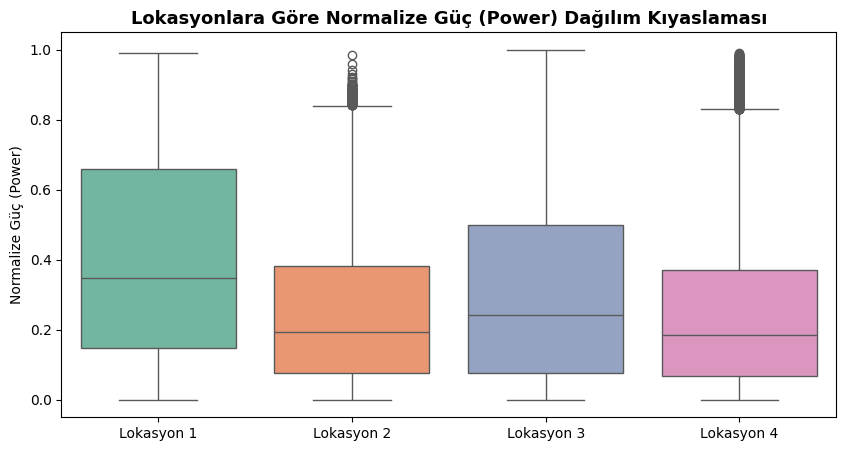

In [8]:
# SADECE POWER DAĞILIMLARI KIYASLAMA
plt.figure(figsize=(10, 5))

power_data = pd.DataFrame({name: df['Power'] for name, df in datasets.items()})
sns.boxplot(data=power_data, palette="Set2")

plt.title("Lokasyonlara Göre Normalize Güç (Power) Dağılım Kıyaslaması", fontsize=13, fontweight='bold')
plt.ylabel("Normalize Güç (Power)")
plt.savefig("power_boxplot_comparison.png", dpi=300)
plt.show()
